
RETIREMENT SIMULATION (Withdrawals start at END of Year 1, capped by available corpus)
Assumptions: Returns applied first for full year, then withdrawal, then remainder is next year's start

▶ 1) 6Cr, return 7%, inflation 5%
   Fund exhausts in year: Never (perpetual)
--------------------------------------------------------------------------------------------------------------
Year   Start Corpus (Cr)  After Returns (Cr) Planned Wd (L)   Actual Wd (L)    End Corpus (Cr)    Status
--------------------------------------------------------------------------------------------------------------
0      6.00               6.00               0.00             0.00             6.00               (start of retirement)
1      6.00               6.42               12.00            12.00            6.30               
2      6.30               6.74               12.60            12.60            6.62               
3      6.62               7.08               13.23            13.23            6.95  

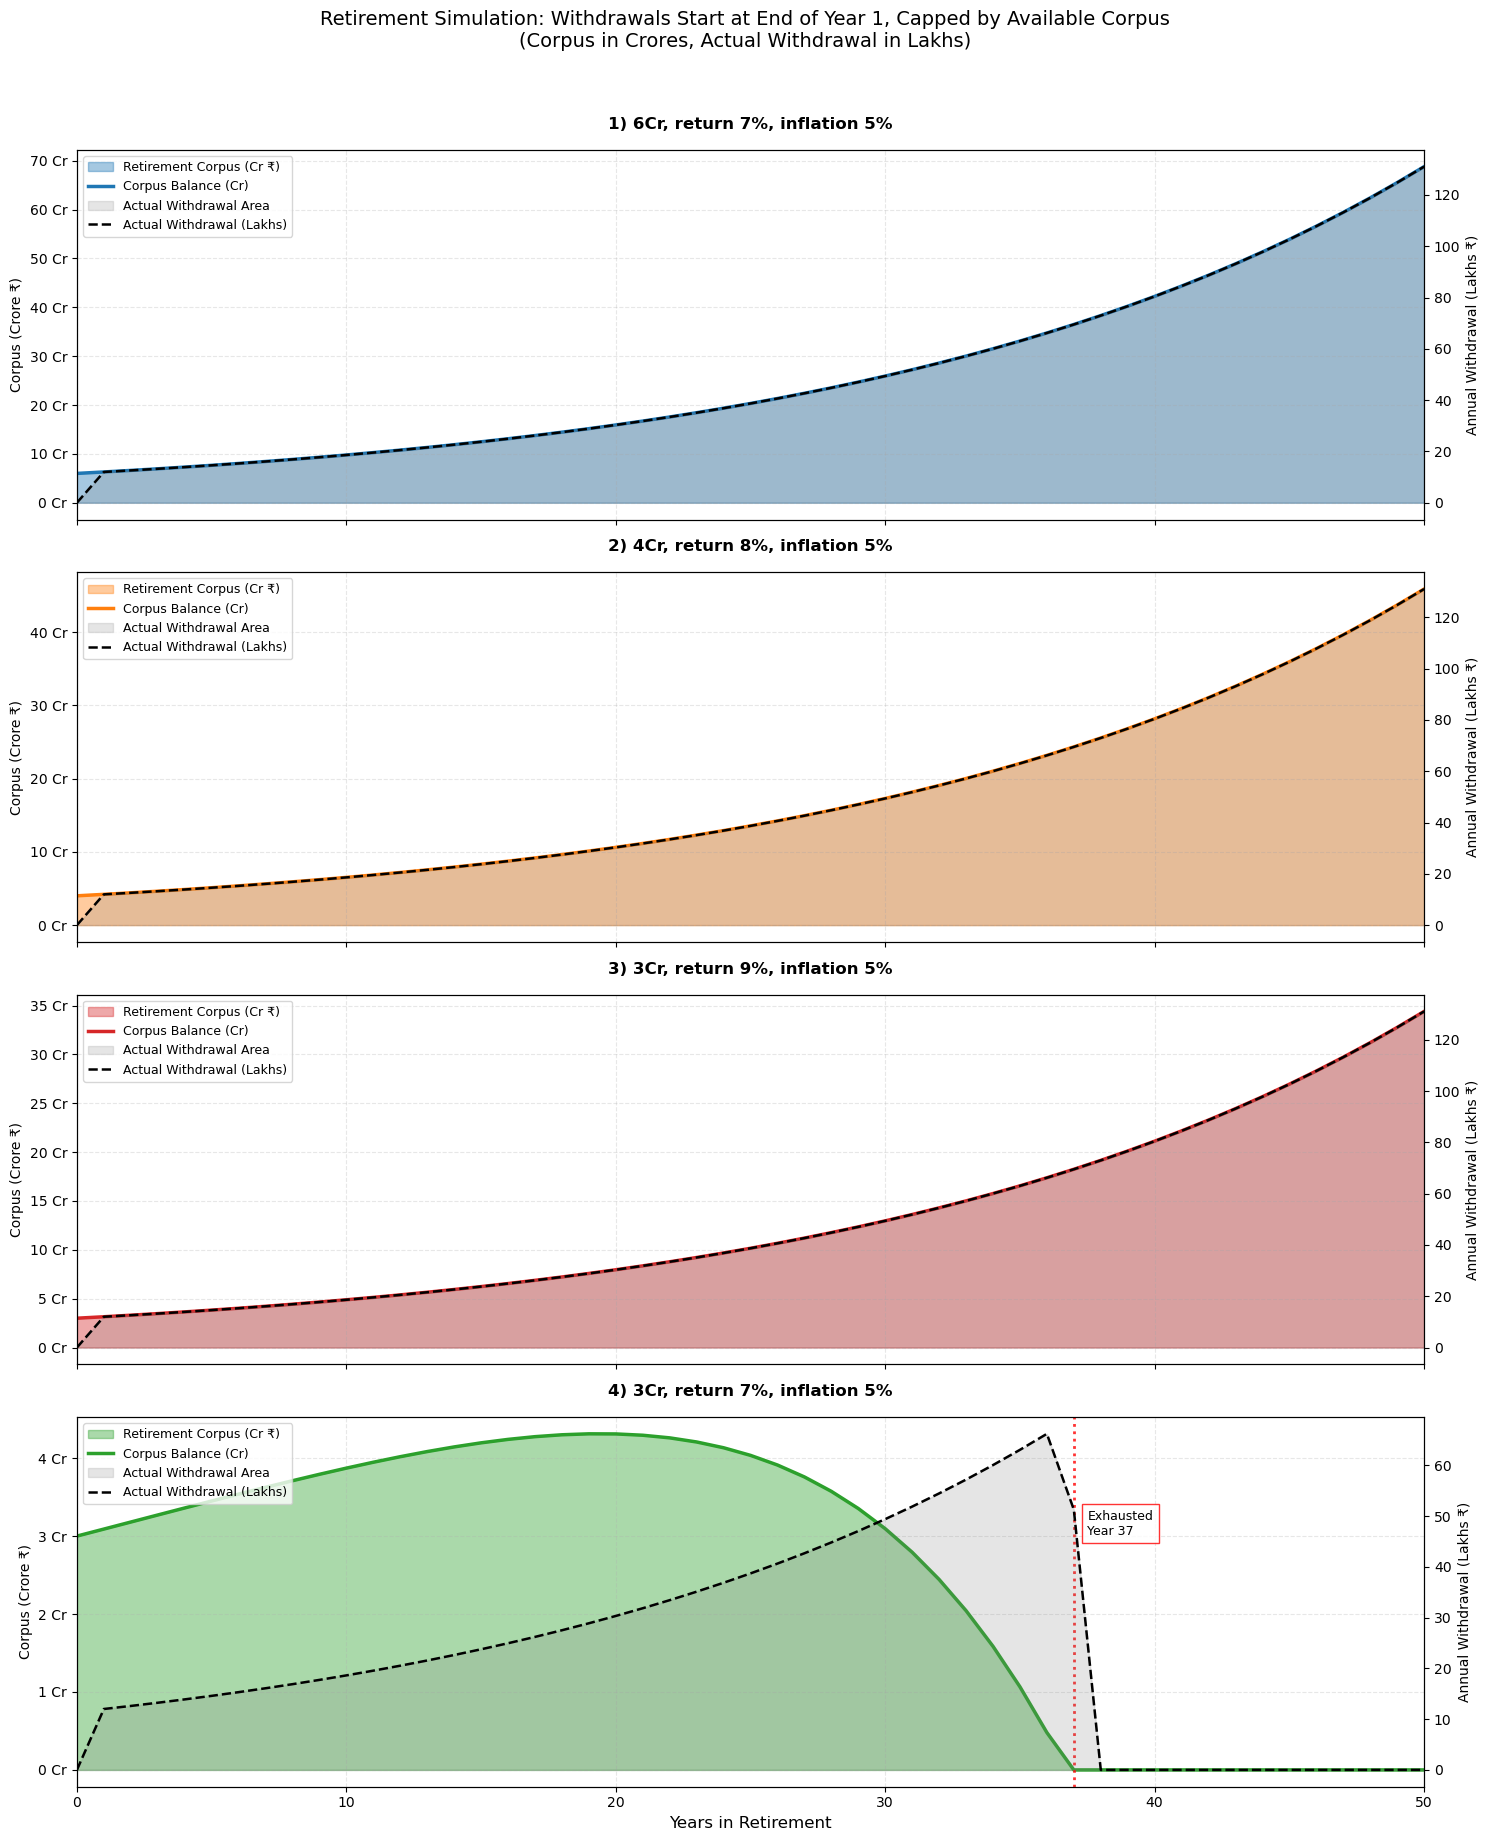

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# -------------------------------------------------------------
# Scenario parameters (all inflation = 5%, returns as shown)
# -------------------------------------------------------------
scenarios = {
    "1) 6Cr, return 7%, inflation 5%": {
        "corpus_start": 6_00_00_000,
        "withdrawal_start": 12_00_000,
        "return_rate": 0.07,
        "inflation_rate": 0.05,
    },
    "2) 4Cr, return 8%, inflation 5%": {
        "corpus_start": 4_00_00_000,
        "withdrawal_start": 12_00_000,
        "return_rate": 0.08,
        "inflation_rate": 0.05,
    },
    "3) 3Cr, return 9%, inflation 5%": {
        "corpus_start": 3_00_00_000,
        "withdrawal_start": 12_00_000,
        "return_rate": 0.09,
        "inflation_rate": 0.05,
    },
    "4) 3Cr, return 7%, inflation 5%": {
        "corpus_start": 3_00_00_000,
        "withdrawal_start": 12_00_000,
        "return_rate": 0.07,
        "inflation_rate": 0.05,
    },
}

years = 50

# -------------------------------------------------------------
# Corrected simulation: Withdrawals start at end of Year 1
# -------------------------------------------------------------
def simulate_corrected(scenario_params, years):
    corpus_eoy = np.zeros(years + 1)      # End-of-year corpus
    withdrawal_planned = np.zeros(years + 1)
    withdrawal_actual = np.zeros(years + 1)
    annual_return = scenario_params["return_rate"]
    inflation = scenario_params["inflation_rate"]
    
    # Year 0: Start of retirement, no withdrawal yet
    corpus_eoy[0] = scenario_params["corpus_start"]
    withdrawal_planned[0] = 0
    withdrawal_actual[0] = 0
    
    for t in range(1, years + 1):
        if corpus_eoy[t-1] <= 0:
            corpus_eoy[t] = 0
            withdrawal_planned[t] = 0
            withdrawal_actual[t] = 0
            continue
        
        # Start of year corpus = previous end-of-year
        start_corpus = corpus_eoy[t-1]
        
        # Apply returns for the full year
        corpus_before_withdrawal = start_corpus * (1 + annual_return)
        
        # Planned withdrawal (inflation-adjusted) - first withdrawal at t=1 has no inflation
        withdrawal_planned[t] = withdrawal_start * ((1 + inflation) ** (t-1))
        
        # Actual withdrawal is capped at available
        withdrawal_actual[t] = min(withdrawal_planned[t], corpus_before_withdrawal)
        
        # End of year corpus after withdrawal
        corpus_eoy[t] = corpus_before_withdrawal - withdrawal_actual[t]
        
        if corpus_eoy[t] < 0:
            corpus_eoy[t] = 0
    
    return corpus_eoy, withdrawal_planned, withdrawal_actual

# -------------------------------------------------------------
# Run simulations
# -------------------------------------------------------------
results = {}
exhaustion_years = {}
withdrawal_start = 12_00_000

for name, params in scenarios.items():
    corpus, withdrawal_planned, withdrawal_actual = simulate_corrected(params, years)
    results[name] = {
        "corpus": corpus, 
        "withdrawal_planned": withdrawal_planned,
        "withdrawal_actual": withdrawal_actual
    }
    
    # Find exhaustion year (when corpus hits zero)
    exhaust_year = None
    for t in range(1, len(corpus)):
        if corpus[t] == 0 and corpus[t-1] > 0:
            exhaust_year = t
            break
    exhaustion_years[name] = exhaust_year

# -------------------------------------------------------------
# Print comprehensive table
# -------------------------------------------------------------
print("\n" + "="*110)
print("RETIREMENT SIMULATION (Withdrawals start at END of Year 1, capped by available corpus)")
print("Assumptions: Returns applied first for full year, then withdrawal, then remainder is next year's start")
print("="*110)

for name, data in results.items():
    corpus_cr = data["corpus"] / 1e7
    withdrawal_planned_lakh = data["withdrawal_planned"] / 1e5
    withdrawal_actual_lakh = data["withdrawal_actual"] / 1e5
    exhaust_yr = exhaustion_years[name]
    
    print(f"\n▶ {name}")
    print(f"   Fund exhausts in year: {exhaust_yr if exhaust_yr else 'Never (perpetual)'}")
    print("-" * 110)
    
    # Determine rows to show
    years_to_show = []
    
    # Initial 5 years (Year 0 to Year 4)
    years_to_show.extend(range(0, min(5, len(corpus_cr))))
    
    # Middle year (Year 25)
    if len(corpus_cr) > 25:
        years_to_show.append(25)
    
    # Exhaustion period or last years
    if exhaust_yr:
        start_exhaust = max(0, exhaust_yr - 6)
        end_exhaust = min(exhaust_yr + 1, len(corpus_cr))
        years_to_show.extend(range(start_exhaust, end_exhaust))
    else:
        # Last 5 years (45-50)
        for y in range(45, min(51, len(corpus_cr))):
            years_to_show.append(y)
    
    years_to_show = sorted(set(years_to_show))
    
    # Print header
    print(f"{'Year':<6} {'Start Corpus (Cr)':<18} {'After Returns (Cr)':<18} {'Planned Wd (L)':<16} {'Actual Wd (L)':<16} {'End Corpus (Cr)':<18} {'Status'}")
    print("-" * 110)
    
    for y in years_to_show:
        if y == 0:
            # Year 0: No growth, no withdrawal
            start_corpus_cr = corpus_cr[0]
            after_returns_cr = corpus_cr[0]
            planned_wd = 0
            actual_wd = 0
            end_corpus_cr = corpus_cr[0]
            status = "(start of retirement)"
        else:
            # Calculate start corpus (previous end)
            start_corpus_cr = corpus_cr[y-1] if y > 0 else corpus_cr[0]
            after_returns_cr = start_corpus_cr * (1 + scenarios[name]["return_rate"])
            planned_wd = withdrawal_planned_lakh[y]
            actual_wd = withdrawal_actual_lakh[y]
            end_corpus_cr = corpus_cr[y]
            
            if y == exhaust_yr and exhaust_yr:
                status = "→ EXHAUSTED"
            elif y > exhaust_yr if exhaust_yr else False:
                status = "(exhausted)"
            elif actual_wd < planned_wd and actual_wd > 0:
                status = "shortfall"
            else:
                status = ""
        
        # Formatting
        if y == 0:
            print(f"{y:<6} {start_corpus_cr:<18.2f} {after_returns_cr:<18.2f} {planned_wd:<16.2f} {actual_wd:<16.2f} {end_corpus_cr:<18.2f} {status}")
        else:
            print(f"{y:<6} {start_corpus_cr:<18.2f} {after_returns_cr:<18.2f} {planned_wd:<16.2f} {actual_wd:<16.2f} {end_corpus_cr:<18.2f} {status}")
    
    print("-" * 110)

# -------------------------------------------------------------
# Plotting: Stacked Area Chart
# -------------------------------------------------------------
fig, axes = plt.subplots(4, 1, figsize=(15, 18), sharex=True)
years_range = np.arange(years + 1)
colors_corpus = ["#1f77b4", "#ff7f0e", "#d62728", "#2ca02c"]

for idx, (name, data) in enumerate(results.items()):
    ax = axes[idx]
    
    corpus_cr = data["corpus"] / 1e7
    withdrawal_actual_lakh = data["withdrawal_actual"] / 1e5
    
    # Stacked area for corpus
    ax.fill_between(years_range, 0, corpus_cr, 
                     color=colors_corpus[idx], alpha=0.4, label="Retirement Corpus (Cr ₹)")
    ax.plot(years_range, corpus_cr, color=colors_corpus[idx], linewidth=2.5, 
            label="Corpus Balance (Cr)")
    
    # Secondary axis for actual withdrawal
    ax2 = ax.twinx()
    ax2.fill_between(years_range, 0, withdrawal_actual_lakh, 
                     color="gray", alpha=0.2, label="Actual Withdrawal Area")
    ax2.plot(years_range, withdrawal_actual_lakh, color="black", linestyle="--", 
             linewidth=1.8, label=f"Actual Withdrawal (Lakhs)")
    ax2.set_ylabel("Annual Withdrawal (Lakhs ₹)", fontsize=10, color="black")
    ax2.tick_params(axis='y', labelcolor="black")
    
    # Mark exhaustion
    exhaust = exhaustion_years[name]
    if exhaust:
        ax.axvline(x=exhaust, color='red', linestyle=':', linewidth=2, alpha=0.8)
        ax.text(exhaust + 0.5, max(corpus_cr[:exhaust+1]) * 0.7, f'Exhausted\nYear {exhaust}', 
                fontsize=9, bbox=dict(facecolor='white', alpha=0.8, edgecolor='red'))
    
    # Formatting
    ax.set_title(name, fontsize=12, fontweight='bold', pad=15)
    ax.set_ylabel("Corpus (Crore ₹)", fontsize=10)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x)} Cr'))
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.set_xlim(0, years)
    
    # Combined legend
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9)

axes[-1].set_xlabel("Years in Retirement", fontsize=12)
plt.suptitle("Retirement Simulation: Withdrawals Start at End of Year 1, Capped by Available Corpus\n(Corpus in Crores, Actual Withdrawal in Lakhs)", 
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


RETIREMENT SIMULATION (Withdrawals start at END of Year 1, capped by available corpus)

▶ 1) 6Cr, return 7%, inflation 5%
   Fund exhausts in year: Never (perpetual)
--------------------------------------------------------------------------------
Year   Corpus (Cr)     Withdrawal (Cr) Status
--------------------------------------------------------------------------------
0      6.00            0.00            (start, no withdrawal)
1      6.30            0.12            
2      6.62            0.13            
3      6.95            0.13            
4      7.29            0.14            
25     20.32           0.39            
45     53.91           1.03            
46     56.61           1.08            
47     59.44           1.13            
48     62.41           1.19            
49     65.53           1.25            
50     68.80           1.31            
--------------------------------------------------------------------------------

▶ 2) 4Cr, return 8%, inflation 5%
   Fund

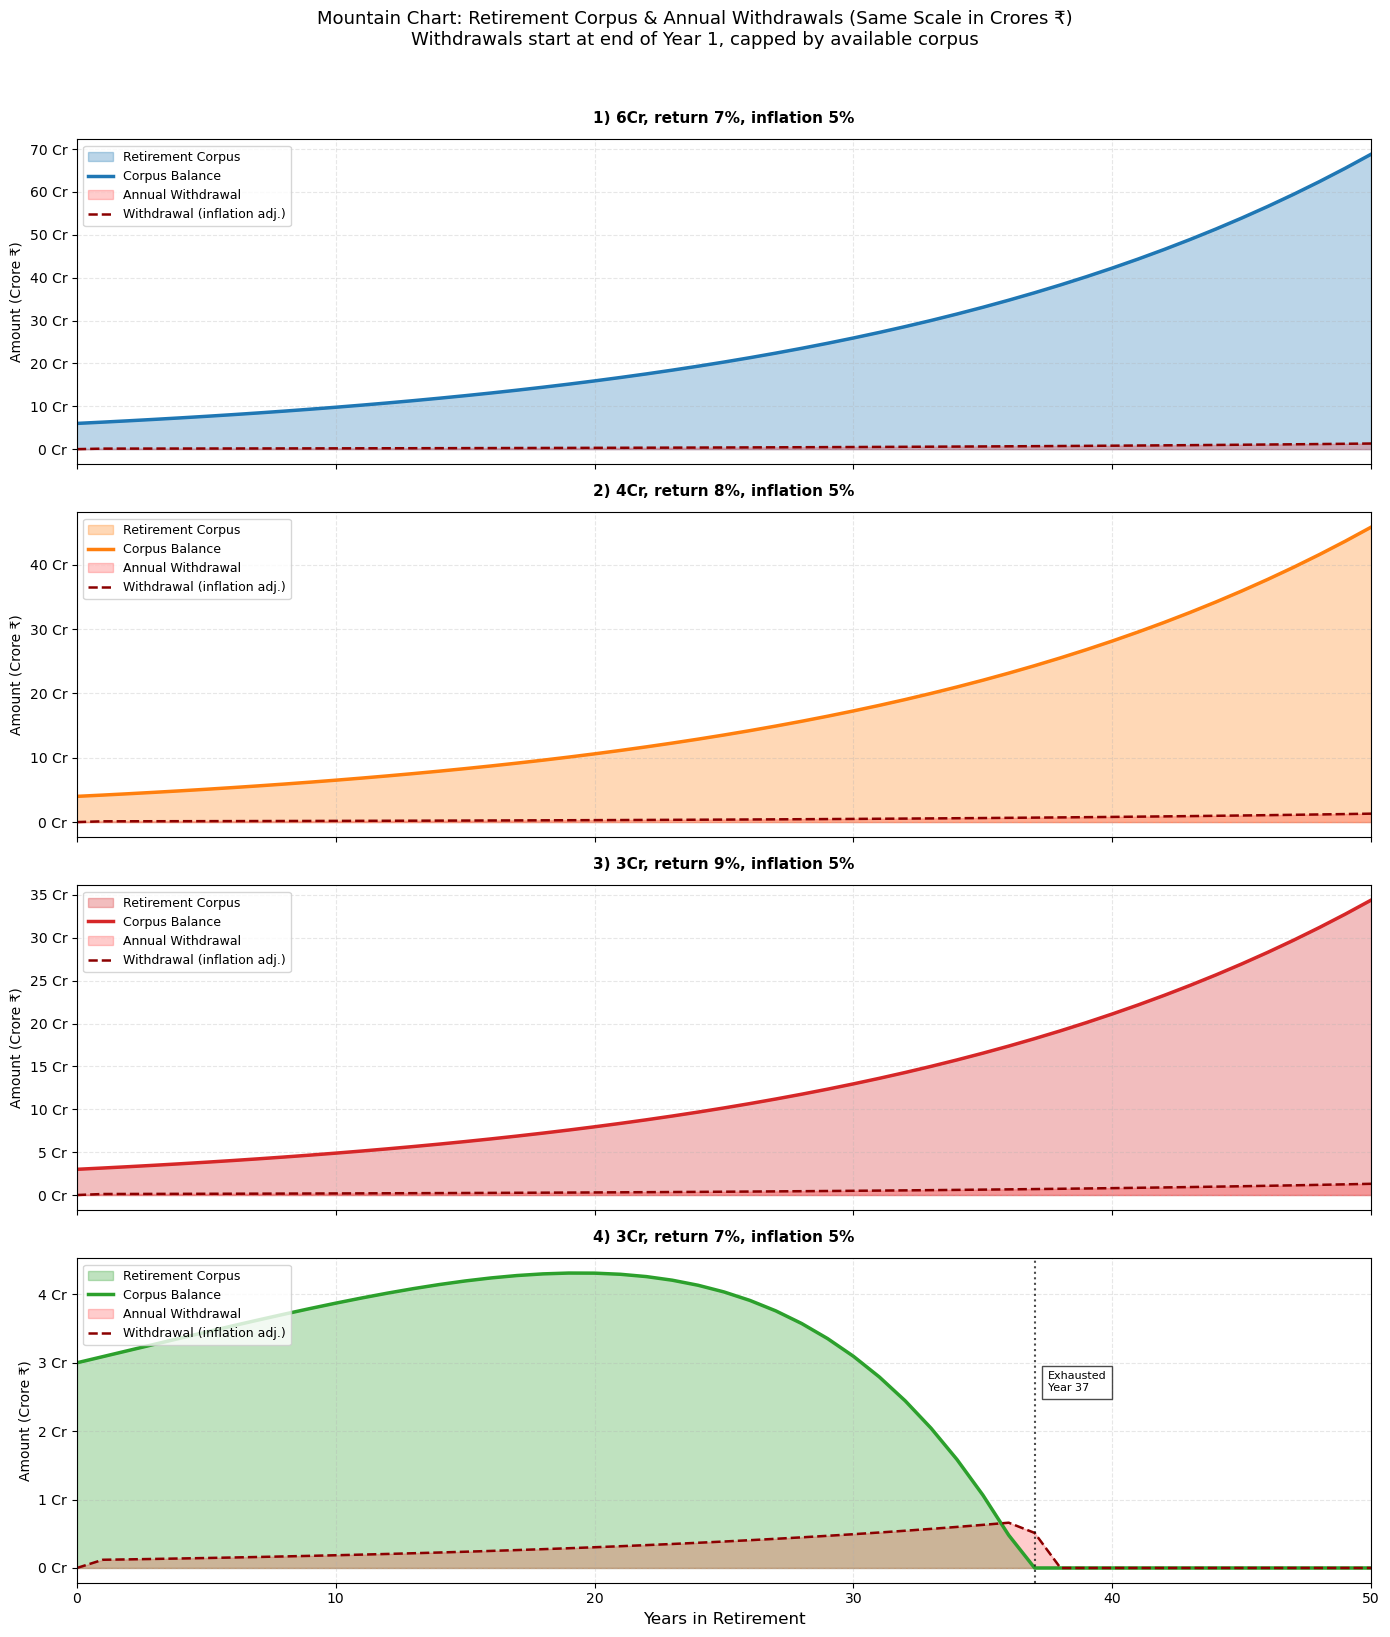

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# -------------------------------------------------------------
# Scenario parameters (all inflation = 5%)
# -------------------------------------------------------------
scenarios = {
    "1) 6Cr, return 7%, inflation 5%": {
        "corpus_start": 6_00_00_000,
        "withdrawal_start": 12_00_000,
        "return_rate": 0.07,
        "inflation_rate": 0.05,
    },
    "2) 4Cr, return 8%, inflation 5%": {
        "corpus_start": 4_00_00_000,
        "withdrawal_start": 12_00_000,
        "return_rate": 0.08,
        "inflation_rate": 0.05,
    },
    "3) 3Cr, return 9%, inflation 5%": {
        "corpus_start": 3_00_00_000,
        "withdrawal_start": 12_00_000,
        "return_rate": 0.09,
        "inflation_rate": 0.05,
    },
    "4) 3Cr, return 7%, inflation 5%": {
        "corpus_start": 3_00_00_000,
        "withdrawal_start": 12_00_000,
        "return_rate": 0.07,
        "inflation_rate": 0.05,
    },
}

years = 50

# -------------------------------------------------------------
# Simulation: Withdrawals start at end of Year 1, capped
# -------------------------------------------------------------
def simulate(scenario_params, years):
    corpus_eoy = np.zeros(years + 1)
    withdrawal_actual = np.zeros(years + 1)
    annual_return = scenario_params["return_rate"]
    inflation = scenario_params["inflation_rate"]
    withdrawal_start = scenario_params["withdrawal_start"]
    
    corpus_eoy[0] = scenario_params["corpus_start"]
    withdrawal_actual[0] = 0
    
    for t in range(1, years + 1):
        if corpus_eoy[t-1] <= 0:
            corpus_eoy[t] = 0
            withdrawal_actual[t] = 0
            continue
        
        # Apply returns first
        corpus_before_wd = corpus_eoy[t-1] * (1 + annual_return)
        
        # Planned withdrawal (inflation-adjusted, first withdrawal at t=1 has no inflation)
        planned_wd = withdrawal_start * ((1 + inflation) ** (t-1))
        
        # Actual withdrawal capped
        withdrawal_actual[t] = min(planned_wd, corpus_before_wd)
        
        # End of year corpus
        corpus_eoy[t] = corpus_before_wd - withdrawal_actual[t]
        
        if corpus_eoy[t] < 0:
            corpus_eoy[t] = 0
    
    return corpus_eoy, withdrawal_actual

# -------------------------------------------------------------
# Run simulations
# -------------------------------------------------------------
results = {}
exhaustion_years = {}

for name, params in scenarios.items():
    corpus, withdrawal = simulate(params, years)
    results[name] = {"corpus": corpus, "withdrawal": withdrawal}
    
    # Find exhaustion year
    exhaust = None
    for t in range(1, len(corpus)):
        if corpus[t] == 0 and corpus[t-1] > 0:
            exhaust = t
            break
    exhaustion_years[name] = exhaust

# -------------------------------------------------------------
# Print summary table
# -------------------------------------------------------------
print("\n" + "="*110)
print("RETIREMENT SIMULATION (Withdrawals start at END of Year 1, capped by available corpus)")
print("="*110)

for name, data in results.items():
    corpus_cr = data["corpus"] / 1e7
    withdrawal_cr = data["withdrawal"] / 1e7  # Convert to Crores for consistency
    exhaust_yr = exhaustion_years[name]
    
    print(f"\n▶ {name}")
    print(f"   Fund exhausts in year: {exhaust_yr if exhaust_yr else 'Never (perpetual)'}")
    print("-" * 80)
    
    # Years to show: initial 5, middle, exhaustion period or last 5
    years_to_show = list(range(0, min(5, len(corpus_cr))))
    if len(corpus_cr) > 25:
        years_to_show.append(25)
    
    if exhaust_yr:
        start_exhaust = max(0, exhaust_yr - 5)
        end_exhaust = min(exhaust_yr + 1, len(corpus_cr))
        years_to_show.extend(range(start_exhaust, end_exhaust))
    else:
        years_to_show.extend(range(45, min(51, len(corpus_cr))))
    
    years_to_show = sorted(set(years_to_show))
    
    print(f"{'Year':<6} {'Corpus (Cr)':<15} {'Withdrawal (Cr)':<15} {'Status'}")
    print("-" * 80)
    for y in years_to_show:
        corpus_val = corpus_cr[y]
        wd_val = withdrawal_cr[y]
        
        if y == 0:
            status = "(start, no withdrawal)"
        elif y == exhaust_yr and exhaust_yr:
            status = "→ EXHAUSTED"
        elif y > exhaust_yr if exhaust_yr else False:
            status = "(exhausted)"
        else:
            status = ""
        
        print(f"{y:<6} {corpus_val:<15.2f} {wd_val:<15.2f} {status}")
    print("-" * 80)

# -------------------------------------------------------------
# Plotting: Mountain / Stacked Area Chart (same Y-axis)
# -------------------------------------------------------------
fig, axes = plt.subplots(4, 1, figsize=(14, 16), sharex=True)
years_range = np.arange(years + 1)
colors = ["#1f77b4", "#ff7f0e", "#d62728", "#2ca02c"]

for idx, (name, data) in enumerate(results.items()):
    ax = axes[idx]
    
    corpus_cr = data["corpus"] / 1e7
    withdrawal_cr = data["withdrawal"] / 1e7  # Same unit: Crores
    
    # Mountain chart: Corpus area
    ax.fill_between(years_range, 0, corpus_cr, 
                     color=colors[idx], alpha=0.3, label="Retirement Corpus")
    ax.plot(years_range, corpus_cr, color=colors[idx], linewidth=2.5, 
            label="Corpus Balance")
    
    # Withdrawal as a filled mountain on same axis (semi-transparent)
    ax.fill_between(years_range, 0, withdrawal_cr, 
                     color="red", alpha=0.2, label="Annual Withdrawal")
    ax.plot(years_range, withdrawal_cr, color="darkred", linestyle="--", 
             linewidth=1.8, label="Withdrawal (inflation adj.)")
    
    # Mark exhaustion
    exhaust = exhaustion_years[name]
    if exhaust:
        ax.axvline(x=exhaust, color='black', linestyle=':', linewidth=1.5, alpha=0.7)
        ax.text(exhaust + 0.5, max(corpus_cr[:exhaust+1]) * 0.6, f'Exhausted\nYear {exhaust}', 
                fontsize=8, bbox=dict(facecolor='white', alpha=0.7, edgecolor='black'))
    
    # Formatting
    ax.set_title(name, fontsize=11, fontweight='bold', pad=12)
    ax.set_ylabel("Amount (Crore ₹)", fontsize=10)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0f} Cr'))
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(loc='upper left', fontsize=9)
    ax.set_xlim(0, years)

axes[-1].set_xlabel("Years in Retirement", fontsize=12)
plt.suptitle("Mountain Chart: Retirement Corpus & Annual Withdrawals (Same Scale in Crores ₹)\nWithdrawals start at end of Year 1, capped by available corpus", 
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()